In [1]:
import os
import cv2
import glob
import random
import numpy as np
import datetime as dt
import tensorflow as tf
import mediapipe as mp
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import *
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.utils import to_categorical, plot_model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

pre-processing

In [2]:
seed_constant = 27
np.random.seed(seed_constant)
random.seed(seed_constant)
tf.random.set_seed(seed_constant)

image_height = 112
image_width = 112
sequence_length = 20

dataset_dir = "dataset_per_kata"

preprocessing: feature extraction

In [4]:
def load_labels(dataset_dir, selected_peraga=None):
    label_map = {}
    
    # Menelusuri semua subfolder kata (AKU, APA, BAGAIMANA, dll.)
    for class_name in sorted(os.listdir(dataset_dir)):
        class_path = os.path.join(dataset_dir, class_name)
        if not os.path.isdir(class_path):
            continue
            
        for file_name in sorted(os.listdir(class_path)):
            if file_name.endswith(".mp4"):
                # Contoh nama file: peraga_1_AKU_01.mp4
                parts = file_name.split("_")
                peraga_name = f"{parts[0]}_{parts[1]}" # Mendapatkan "peraga_1"
                label = parts[2]                      # Mendapatkan "AKU"
                
                # Filter berdasarkan peraga yang dipilih (jika ada)
                if selected_peraga is not None and peraga_name not in selected_peraga:
                    continue
                
                # Simpan path relatif/lengkap ke file dan labelnya
                relative_path = os.path.join(class_name, file_name)
                label_map[relative_path] = label

    return label_map


def frames_extraction(video_path):
    all_frames = []
    video_reader = cv2.VideoCapture(video_path)

    while True:
        success, frame = video_reader.read()
        if not success:
            break

        resized_frame = cv2.resize(frame, (image_width, image_height))
        normalized_frame = resized_frame / 255.0
        all_frames.append(normalized_frame)

    video_reader.release()
    total_read = len(all_frames)

    if total_read == 0:
        return []

    if total_read >= sequence_length:
        indicies = np.linspace(0, total_read - 1, sequence_length).astype(int)
        frames_list = [all_frames[i] for i in indicies]
    else:
        frames_list = list(all_frames) + [all_frames[-1]] * (sequence_length - total_read)

    return frames_list


def create_dataset(dir = dataset_dir):
    label_map = load_labels(dir)
    classes_list = sorted(set(label_map.values()))

    classes_to_index = {}

    for i in range(len(classes_list)):
        name = classes_list[i]
        classes_to_index[name] = i

    features = []
    labels = []

    for file_name, label in label_map.items():
        print(f"extracting data: {file_name} (label: {label})")
        video_file_path = os.path.join(dir, file_name)
        frames = frames_extraction(video_file_path)

        if len(frames) == sequence_length:
            features.append(frames)
            labels.append(classes_to_index[label])
        else:
            print(f"skipped {file_name}")

    features = np.asarray(features)
    labels = np.array(labels)

    return features, labels, classes_list

mediapipe

In [5]:
pose_idx = [0, 11, 12, 13, 14, 15, 16] # face, left shoulder, right shoulder, left elbow, right elbow, left wrist, right wrist
pose_dim = len(pose_idx) * 2
hand_dim = 21 * 2 * 2 + 1

base_dim = pose_dim + 2 * hand_dim

head_dim = 5                   # per frame: valid, qy_top, ring, touch_top, touch_low
head_sum_dim = 2               # per klip: max touch_top, max touch_low
head_start = base_dim

landmark_dim = base_dim + head_dim + 1 + head_sum_dim   # +1 kolom ketukan

left_flag_pos = pose_dim + hand_dim - 1
right_flag_pos = base_dim - 1          # BUKAN landmark_dim - 1, nanti menunjuk kolom ketukan

tap_prominence = 0.3                   # satuan lebar bahu, tuning di data
tap_scale = 4.0                        # supaya nilai fitur kira-kira 0..1

tap_rel_prominence = 0.08   # puncak dihitung jika >= 8% dari puncak terbesar (tuning, lihat sel diagnostik)
tap_min_abs = 0.05          # lantai absolut agar noise datar tidak ikut

shoulder_vis_threshold = 0.3
max_process_width = 640

ear_vis_threshold = 0.5
wrist_vis_threshold = 0.3
head_rx_scale = 1.15           # setengah lebar kepala = jarak telinga / 2 * ini
head_ry_scale = 1.45           # tinggi elips relatif ke rx (1.0 = lingkaran murni)
head_cy_shift = 0.0            # geser pusat vertikal (satuan rx, negatif = naik)
head_smooth = 0.5              # EMA, makin besar makin halus tapi lag
touch_tol = 0.25               # toleransi "menyentuh" di luar elips (satuan jari-jari)
top_zone = -0.45               # q_y < ini  = dahi / ubun-ubun
low_zone = 0.30                # q_y > ini  = hidung / mulut / dagu / bawah


def new_holistic():
    return mp.solutions.holistic.Holistic(static_image_mode = False, model_complexity = 1, smooth_landmarks = True, min_detection_confidence = 0.5, min_tracking_confidence = 0.5)


def lm_xy(landmark_list, idx = None, aspect = 1.0):
    pts = landmark_list.landmark
    if idx is not None:
        pts = [pts[i] for i in idx]
    return np.array([[p.x * aspect, p.y] for p in pts], dtype = np.float32)


def hand_vector(hand_landmarks, center, scale, aspect = 1.0):
    if hand_landmarks is None:
        return np.zeros(hand_dim, dtype = np.float32)

    xy = lm_xy(hand_landmarks, aspect = aspect)
    body = (xy - center) / scale
    rel = xy - xy[0]
    extent = np.abs(rel).max()
    if extent > 1e-6:
        rel = rel / extent
    return np.concatenate([body.flatten(), rel.flatten(), [1.0]]).astype(np.float32)


def update_head(results, prev, aspect):
    # elips kepala dari telinga pose, dihaluskan EMA, fallback ke frame sebelumnya
    if results.pose_landmarks is None:
        return prev

    lm = results.pose_landmarks.landmark
    if lm[7].visibility < ear_vis_threshold or lm[8].visibility < ear_vis_threshold:
        return prev

    ears = lm_xy(results.pose_landmarks, [7, 8], aspect)
    ear_dist = float(np.linalg.norm(ears[0] - ears[1]))
    if ear_dist < 1e-3:
        return prev

    rx = ear_dist / 2.0 * head_rx_scale
    ry = rx * head_ry_scale
    c = ears.mean(axis = 0) + np.array([0.0, head_cy_shift * rx], dtype = np.float32)
    new = np.array([c[0], c[1], rx, ry], dtype = np.float32)

    if prev is None:
        return new
    return head_smooth * prev + (1.0 - head_smooth) * new


def head_features(results, head, aspect):
    # [valid, qy_top, ring, touch_top, touch_low]; q = koordinat dalam satuan elips kepala
    out = np.zeros(head_dim, dtype = np.float32)
    if head is None:
        return out

    center, radius = head[:2], head[2:4]

    hands = []
    for hand in (results.left_hand_landmarks, results.right_hand_landmarks):
        if hand is not None:
            hands.append(lm_xy(hand, aspect = aspect))

    if not hands and results.pose_landmarks is not None:      # fallback: wrist pose
        lm = results.pose_landmarks.landmark
        wrists = lm_xy(results.pose_landmarks, [15, 16], aspect)
        hands = [wrists[i:i + 1] for i, j in enumerate([15, 16]) if lm[j].visibility > wrist_vis_threshold]

    if not hands:
        return out

    qs = [(pts - center) / radius for pts in hands]
    q = min(qs, key = lambda a: np.linalg.norm(a, axis = 1).min())   # tangan terdekat ke kepala

    d = np.linalg.norm(q, axis = 1) - 1.0                  # <0 di dalam elips, >0 di luar
    near = np.exp(-0.5 * (np.maximum(d, 0.0) / touch_tol) ** 2)

    top_mask = q[:, 1] < top_zone
    low_mask = q[:, 1] > low_zone

    out[0] = 1.0
    out[1] = np.clip(q[:, 1].min(), -2.0, 2.0) / 2.0       # titik tertinggi tangan: -1 puncak kepala, 0 setinggi telinga
    out[2] = np.clip(np.abs(d).min(), 0.0, 2.0) / 2.0      # jarak ke garis elips
    out[3] = near[top_mask].max() if top_mask.any() else 0.0
    out[4] = near[low_mask].max() if low_mask.any() else 0.0
    return out


def results_to_vector(results, last_state, aspect = 1.0, head_aspect = 1.0):
    center, scale, pose_vec, head = last_state if last_state is not None else (None, None, None, None)

    if results.pose_landmarks is not None:
        lm = results.pose_landmarks.landmark
        if lm[11].visibility > shoulder_vis_threshold and lm[12].visibility > shoulder_vis_threshold:
            pts = lm_xy(results.pose_landmarks, pose_idx, aspect)
            l_shoulder, r_shoulder = pts[1], pts[2]
            new_scale = float(np.linalg.norm(l_shoulder - r_shoulder))
            if new_scale > 1e-3:
                scale = new_scale
                center = (l_shoulder + r_shoulder) / 2.0
                pose_vec = ((pts - center) / scale).flatten().astype(np.float32)

    head = update_head(results, head, head_aspect)

    if center is None:
        return None, None

    last_state = (center, scale, pose_vec, head)
    left = hand_vector(results.left_hand_landmarks, center, scale, aspect)
    right = hand_vector(results.right_hand_landmarks, center, scale, aspect)
    head_vec = head_features(results, head, head_aspect)

    return np.concatenate([pose_vec, left, right, head_vec]).astype(np.float32), last_state


def select_indices(vectors, sequence = sequence_length):
    valid = [i for i, v in enumerate(vectors) if v is not None]
    if not valid:
        return None

    # tinggi tangan tertinggi per frame (y lebih kecil = lebih tinggi)
    # pose_vec: index 10,11 = wrist kiri (x,y), 12,13 = wrist kanan (x,y)
    h = np.array([min(vectors[i][11], vectors[i][13]) for i in valid])

    k = max(3, len(h) // 10)
    rest = max(np.median(h[:k]), np.median(h[-k:]))   # posisi tangan istirahat
    top = h.min()                                     # posisi tertinggi

    if rest - top > 0.3:                              # ada gerakan terangkat yang jelas
        thr = rest - 0.35 * (rest - top)
        raised = [valid[j] for j in range(len(valid)) if h[j] < thr]
        span = raised
        pad = 2                                       # sisakan sedikit awal/akhir gerakan
        start = max(valid[0], span[0] - pad)
        end = min(valid[-1], span[-1] + pad)
    else:
        # fallback: cara lama (berdasarkan deteksi tangan)
        active = [i for i in valid
                  if vectors[i][left_flag_pos] == 1.0 or vectors[i][right_flag_pos] == 1.0]
        span = active if active else valid
        start, end = span[0], span[-1]

    return np.linspace(start, end, sequence).round().astype(int).tolist()
    

def forward_fill(vectors, indices):
    picked = []

    for i in indices:
        v = vectors[i]

        if v is None:
            j = i

            while j >= 0 and vectors[j] is None:
                j -= 1

            if j < 0:
                j = i

                while j < len(vectors) and vectors[j] is None:
                    j += 1

            v = vectors[j]
        picked.append(v)
    return np.stack(picked)


def count_taps(vectors, start, end):
    seg = forward_fill(vectors, list(range(start, end + 1)))
    y = seg[:, [11, 13]].mean(axis=1)          # y wrist kiri & kanan (sudah dinormalisasi bahu)
    if len(y) < 7:
        return 0
    y = savgol_filter(y, 7, 2)
    peaks, _ = find_peaks(-y, prominence=tap_prominence, distance=3)
    return len(peaks)


def landmark_sequence(vectors, indices):
    seq = forward_fill(vectors, indices)
    taps = count_taps(vectors, indices[0], indices[-1]) / tap_scale

    head_cols = seq[:, head_start:head_start + head_dim]
    head_sum = np.array([head_cols[:, 3].max(), head_cols[:, 4].max()], dtype = np.float32)

    return np.hstack([
        seq,
        np.full((len(seq), 1), taps, np.float32),
        np.tile(head_sum, (len(seq), 1)),
    ])


def process_frame_live(frame, holistic, last_state):
    height, width = frame.shape[:2]
    proc = frame

    if width > max_process_width:
        proc = cv2.resize(frame, (max_process_width, int(height * max_process_width / width)))

    results = holistic.process(cv2.cvtColor(proc, cv2.COLOR_BGR2RGB))
    vector, last_state = results_to_vector(results, last_state, head_aspect = width / height)

    small = cv2.resize(frame, (image_width, image_height)) / 255.0

    return small.astype(np.float32), vector, last_state, results


def read_and_detect(video_path, keep_full_frames = False):
    small_frames, vectors, raw = [], [], []
    full_frames = []
    cap = cv2.VideoCapture(video_path)
    last_state = None

    with new_holistic() as holistic:
        while True:
            ok, frame = cap.read()

            if not ok:
                break

            small, vector, last_state, results = process_frame_live(frame, holistic, last_state)
            vectors.append(vector)
            small_frames.append(small)

            if keep_full_frames: # kemungkinan bisa dihapus
                height, width = frame.shape[:2]
                proc = frame

                if width > max_process_width:
                    proc = cv2.resize(frame, (max_process_width, int(height * max_process_width / width)))

                full_frames.append(proc)
                raw.append(results)

    cap.release()
    return small_frames, vectors, full_frames, raw


def landmarks_extraction(video_path, sequence = sequence_length):
    small_frames, vectors, _, _ = read_and_detect(video_path)

    if not small_frames:
        return None, None

    indices = select_indices(vectors, sequence)

    if indices is None:
        return None, None

    landmark_seq = landmark_sequence(vectors, indices)
    frame_seq = np.stack([small_frames[i] for i in indices]).astype(np.float32)

    return frame_seq, landmark_seq


def create_dataset_pose(dir = dataset_dir, selected_peraga = None, cache_path = "pose_cache.npz", force_recompute = False):
    # Tambahkan parameter selected_peraga ke load_labels
    label_map = load_labels(dir, selected_peraga=selected_peraga)

    classes_list = sorted(set(label_map.values()))

    # Jika ingin pakai cache per set (train/test), buat nama cache dinamis
    if selected_peraga is not None:
        cache_path = f"pose_4_peraga_prominence_{'_'.join(selected_peraga)}.npz"

    if os.path.exists(cache_path) and not force_recompute:
        data = np.load(cache_path, allow_pickle = True)
        if list(data["classes"]) == classes_list and data["landmarks"].shape[-1] == landmark_dim:
            print(f"using cache file: {cache_path}")
            return data["frames"], data["landmarks"], data["labels"], classes_list

    classes_to_index = {name: i for i, name in enumerate(classes_list)}

    frames_all, landmarks_all, labels = [], [], []

    for file_path, label in label_map.items():
        print(f"pose and hands extraction: {file_path} (label: {label})")
        full_video_path = os.path.join(dir, file_path)
        frames, landmarks = landmarks_extraction(full_video_path)

        if frames is None:
            print("skipped (no pose / hands detected)")
            continue

        frames_all.append(frames)
        landmarks_all.append(landmarks)
        labels.append(classes_to_index[label])

    frames_all = np.asarray(frames_all, dtype = np.float32)
    landmarks_all = np.asarray(landmarks_all, dtype = np.float32)
    labels = np.array(labels)

    np.savez_compressed(cache_path, frames = frames_all, landmarks = landmarks_all, labels = labels, classes = np.array(classes_list))
    print(f"saved cache file: {cache_path}")

    return frames_all, landmarks_all, labels, classes_list


def visualize_video_pose(video_path, out_path = "pose_debug.png", sequence = sequence_length, cols = 5):

    mediapipe_draw = mp.solutions.drawing_utils
    mediapipe_holistic = mp.solutions.holistic

    _, vectors, full_frames, raw = read_and_detect(video_path, keep_full_frames = True)
    indices = select_indices(vectors, sequence)

    if indices is None:
        print("no pose / hands detected")
        return

    titles = []

    frame_h, frame_w = full_frames[0].shape[:2]
    aspect = frame_w / frame_h
    heads, h = [], None

    for r_ in raw:
        h = update_head(r_, h, aspect)
        heads.append(h)

    for t, i in enumerate(indices):
        image = full_frames[i].copy()
        
        r = raw[i]

        mediapipe_draw.draw_landmarks(image, r.pose_landmarks, mediapipe_holistic.POSE_CONNECTIONS)
        mediapipe_draw.draw_landmarks(image, r.left_hand_landmarks, mediapipe_holistic.HAND_CONNECTIONS)
        mediapipe_draw.draw_landmarks(image, r.right_hand_landmarks, mediapipe_holistic.HAND_CONNECTIONS)

        h = heads[i]

        if h is not None:
            fh = image.shape[0]                  # 1 satuan aspect-space = tinggi frame (piksel)
            cv2.ellipse(image, (int(h[0] * fh), int(h[1] * fh)), (int(h[2] * fh), int(h[3] * fh)), 0, 0, 360, (255, 0, 255), 2)
            hf = head_features(r, h, aspect)

        image = cv2.resize(image, (240, 180))

        if r.left_hand_landmarks:
            left_status = "L"
        else:
            left_status = "-"

        if r.right_hand_landmarks:
            right_status = "R"
        else:
            right_status = "-"

        det = left_status + right_status

        text_info = f"t={t} f={i} {det}" #time, frames, detected hands
        
        if h is not None:
            cv2.putText(image, f"top={hf[3]:.2f} low={hf[4]:.2f}", (5, 32), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 0, 255), 1)

        titles.append(image)

    while len(titles) % cols:
        titles.append(np.zeros_like(titles[0]))

    rows = [np.hstack(titles[k:k + cols]) for k in range(0, len(titles), cols)]
    cv2.imwrite(out_path, np.vstack(rows))

    print(f"saved debug image: {out_path}")


def vgg_preprocessing(x):
    return preprocess_input(x * 255.0)

models (cnn+lstm)

In [18]:

def landmark_branch(landmark_input, units = 128):

    # cnn
    x = tf.keras.layers.GaussianNoise(0.02)(landmark_input)
    x = tf.keras.layers.Conv1D(filters=64, kernel_size=3, padding = "same", activation="relu")(landmark_input) 
    x = LayerNormalization()(x)

    return Dropout(0.3)(x)


def temporal_head(x, num_classes):

    # lstm layer
    x = tf.keras.layers.LSTM(64, return_sequences=True, dropout=0.2)(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = Dropout(0.4)(x)
    x = Dense(64, activation = "relu")(x)
    x = Dropout(0.3)(x)

    # softmax
    return Dense(num_classes, activation = "softmax")(x)


def create_pose_lstm(num_classes):
    landmark_input = tf.keras.layers.Input(shape = (sequence_length, landmark_dim), name = "landmarks")
    x = landmark_branch(landmark_input)
    out = temporal_head(x, num_classes)

    model = Model(landmark_input, out, name = "pose_hand_lstm")
    model.summary()

    return model


def create_fusion(num_classes):
    frame_input = tf.keras.layers.Input(shape = (sequence_length, image_height, image_width, 3), name = "frames")
    landmark_input = tf.keras.layers.Input(shape = (sequence_length, landmark_dim), name = "landmarks")

    vgg = VGG16(weights = "imagenet", include_top = False, input_shape = (image_height, image_width, 3))
    vgg.trainable = False

    f = tf.keras.layers.TimeDistributed(tf.keras.layers.Lambda(vgg_preprocessing))(frame_input)
    f = tf.keras.layers.TimeDistributed(vgg)(f)
    f = tf.keras.layers.TimeDistributed(GlobalAveragePooling2D())(f)
    f = Dropout(0.3)(f)
    f = tf.keras.layers.TimeDistributed(Dense(64, activation = "relu"))(f)

    l = landmark_branch(landmark_input)

    x = tf.keras.layers.Concatenate()([f, l])
    out = temporal_head(x, num_classes)

    model = Model([frame_input, landmark_input], out, name = "fusion_vgg16_model")
    model.summary()
    return model


if __name__ == "__main__":
    dataset_dir = "dataset_per_kata"
    
    train_peraga = ["peraga_1", "peraga_2", "peraga_3"]
    test_peraga  = ["peraga_4"]

    print(f"--- MEMUAT DATA TRAINING ({train_peraga}) ---")
    x_train_frames, x_train, y_train_raw, classes_list = create_dataset_pose(
        dataset_dir, selected_peraga=train_peraga, cache_path="cache_train.npz"
    )
    
    # Seterusnya proses model training seperti biasa...
    
    print(f"\n--- MEMUAT DATA TESTING ({test_peraga}) ---")
    x_test_frames, x_test, y_test_raw, _ = create_dataset_pose(
        dataset_dir, selected_peraga=test_peraga, cache_path="cache_test.npz"
    )

    num_classes = len(classes_list)
    print(f"\nNumber of classes: {num_classes}")
    print(f"Classes list: {classes_list}")
    print(f"Train landmarks shape: {x_train.shape}")
    print(f"Test landmarks shape: {x_test.shape}")

    # One-hot encoding labels
    y_train = to_categorical(y_train_raw, num_classes=num_classes)
    y_test = to_categorical(y_test_raw, num_classes=num_classes)

    # Buat dan latih model
    model = create_pose_lstm(num_classes)
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3), 
        loss="categorical_crossentropy", 
        metrics=["accuracy"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss" ,patience=15, mode="min", restore_best_weights=True
    )

    x_tr, x_val, y_tr, y_val = train_test_split(
        x_train, y_train,
        test_size = 0.2,
        stratify = y_train_raw,      # label integer, bukan one-hot
        random_state = seed_constant,
        shuffle = True,
    )

    
    
    history = model.fit(
        x_tr, y_tr,
        validation_data = (x_val, y_val),
        epochs = 300,
        batch_size = 8,
        shuffle = True,
        callbacks = [early_stopping],
    )

    print(" ================================================================ ")
    print("Evaluation on Test")
    model.evaluate(x_test, y_test)

    date = dt.datetime.now().strftime("%d_%m_%Y(%H-%M-%S)")
    model.save(f"model_{date}.h5")

--- MEMUAT DATA TRAINING (['peraga_1', 'peraga_2', 'peraga_3']) ---
using cache file: pose_4_peraga_prominence_peraga_1_peraga_2_peraga_3.npz

--- MEMUAT DATA TESTING (['peraga_4']) ---
using cache file: pose_4_peraga_prominence_peraga_4.npz

Number of classes: 16
Classes list: ['AKU', 'APA', 'BAGAIMANA', 'BELAJAR', 'BERANGKAT', 'DATANG', 'DIA', 'DIMANA', 'INGAT', 'KAMU', 'KAPAN', 'KITA', 'MAKAN', 'MENGAPA', 'MEREKA', 'SIAPA']
Train landmarks shape: (480, 20, 192)
Test landmarks shape: (160, 20, 192)
Model: "pose_hand_lstm"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 landmarks (InputLayer)      [(None, 20, 192)]         0         
                                                                 
 conv1d_8 (Conv1D)           (None, 20, 64)            36928     
                                                                 
 layer_normalization_8 (Laye  (None, 20, 64)           128       
 rNormal

confusion matrix


Total video: 160 | Accuracy: 96.25%

              precision    recall  f1-score   support

         AKU       1.00      1.00      1.00        10
         APA       1.00      0.80      0.89        10
   BAGAIMANA       0.83      1.00      0.91        10
     BELAJAR       0.91      1.00      0.95        10
   BERANGKAT       0.91      1.00      0.95        10
      DATANG       1.00      0.90      0.95        10
         DIA       0.90      0.90      0.90        10
      DIMANA       1.00      1.00      1.00        10
       INGAT       1.00      1.00      1.00        10
        KAMU       0.91      1.00      0.95        10
       KAPAN       1.00      0.90      0.95        10
        KITA       1.00      1.00      1.00        10
       MAKAN       1.00      1.00      1.00        10
     MENGAPA       1.00      1.00      1.00        10
      MEREKA       1.00      0.90      0.95        10
       SIAPA       1.00      1.00      1.00        10

    accuracy                           0.9

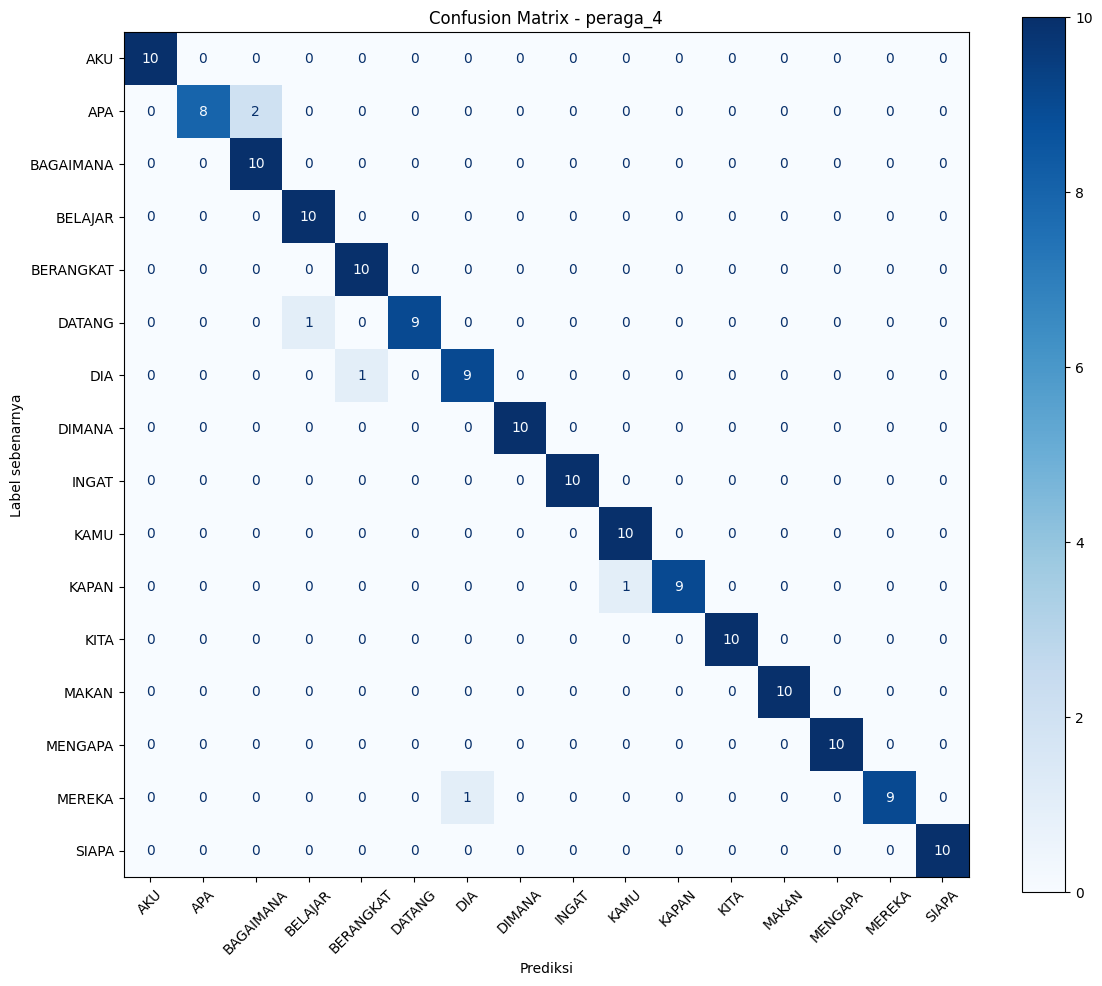


Video salah prediksi:
  peraga_4_APA_06.mp4: APA -> BAGAIMANA
  peraga_4_APA_09.mp4: APA -> BAGAIMANA
  peraga_4_DATANG_08.mp4: DATANG -> BELAJAR
  peraga_4_DIA_07.mp4: DIA -> BERANGKAT
  peraga_4_KAPAN_07.mp4: KAPAN -> KAMU
  peraga_4_MEREKA_02.mp4: MEREKA -> DIA


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ============================== CONFIG ==============================
cm_dataset_dir  = "dataset_per_kata"
cm_test_peraga  = "peraga_4"                                    # ganti: "peraga_2" / "peraga_3"
cm_model_path   = "model_28_11_2026(01-27-58).h5"     # samakan dengan model di cell evaluasi
cm_normalize    = False                                # True = persen per baris (recall), False = jumlah video
cm_save_path    = f"out/confusion_matrix/confusion_matrix_prominence_{cm_test_peraga}.png"
# ====================================================================


def collect_predictions(dataset_dir, test_peraga, model_path):
    classes_list = sorted(set(load_labels(dataset_dir).values()))
    class_to_index = {c: i for i, c in enumerate(classes_list)}
    model = load_model(model_path)

    y_true, y_pred, names = [], [], []
    for class_name in sorted(os.listdir(dataset_dir)):
        class_path = os.path.join(dataset_dir, class_name)
        if not os.path.isdir(class_path):
            continue
        for filename in sorted(os.listdir(class_path)):
            if not (filename.endswith(".mp4") and filename.startswith(test_peraga)):
                continue

            true_label = filename.split("_")[2].upper()
            if true_label not in class_to_index:
                continue

            _, landmarks = landmarks_extraction(os.path.join(class_path, filename))
            if landmarks is None:
                print(f"skipped (tidak terdeteksi): {filename}")
                continue

            prob = model.predict(landmarks[None], verbose=0)[0]
            y_true.append(class_to_index[true_label])
            y_pred.append(int(np.argmax(prob)))
            names.append(filename)

    return np.array(y_true), np.array(y_pred), classes_list, names


def plot_confusion_matrix(y_true, y_pred, classes_list, title, normalize=True, save_path=None):
    labels = list(range(len(classes_list)))
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    if normalize:
        row_sum = cm.sum(axis=1, keepdims=True)
        cm_show = np.divide(cm, row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0)
        values_format = ".0%"
    else:
        cm_show = cm
        values_format = "d"

    fig, ax = plt.subplots(figsize=(12, 10))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_show, display_labels=classes_list)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format=values_format, colorbar=True)
    ax.set_title(title)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label sebenarnya")
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=150)
        print(f"saved: {save_path}")
    plt.show()
    return cm


y_true, y_pred, classes_list, names = collect_predictions(cm_dataset_dir, cm_test_peraga, cm_model_path)

acc = (y_true == y_pred).mean()
print(f"\nTotal video: {len(y_true)} | Accuracy: {acc * 100:.2f}%\n")
print(classification_report(y_true, y_pred, labels = list(range(len(classes_list))), target_names = classes_list, zero_division = 0))

cm = plot_confusion_matrix(
    y_true, y_pred, classes_list,
    title=f"Confusion Matrix - {cm_test_peraga}",
    normalize=cm_normalize,
    save_path=cm_save_path,
)

# daftar video yang salah prediksi
print("\nVideo salah prediksi:")
for n, t, p in zip(names, y_true, y_pred):
    if t != p:
        print(f"  {n}: {classes_list[t]} -> {classes_list[p]}")